In [1]:
# Clone Github repository
!git clone https://github.com/magicleap/SuperGluePretrainedNetwork.git

# Download and extract HPatches Sequences
!wget https://huggingface.co/datasets/vbalnt/hpatches/resolve/main/hpatches-sequences-release.zip
!7z x hpatches-sequences-release.zip

fatal: destination path 'SuperGluePretrainedNetwork' already exists and is not an empty directory.
zsh:1: command not found: wget
zsh:1: command not found: 7z


Image 1 shape: (320, 400, 3)
Image 2 shape: (320, 400, 3)
Points shape: (5, 2)


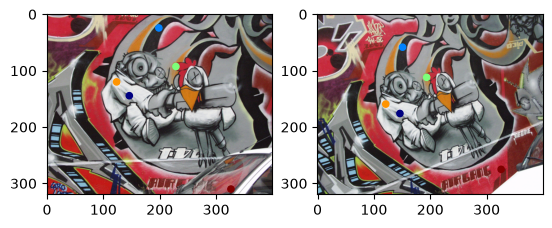

In [2]:
import cv2 , matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm

category = "v_bird"
image1_path = f"graf/img1.ppm"
image2_path = f"graf/img2.ppm"
H12_path = f"graf/H1to2p.txt"


image1 = cv2.imread(image1_path, 1) # 0: grayscale | 1: bgr
image2 = cv2.imread(image2_path, 1) # 0: grayscale | 1: bgr
H = np.loadtxt(H12_path)

print("Image 1 shape:", image1.shape)
print("Image 2 shape:", image2.shape)

h1, w1 = image1.shape[:2]
h2, w2 = image2.shape[:2]

num_points = 5
np.random.seed(58) 
pts = np.random.rand(num_points, 2,) * np.array([w1,h1])
print("Points shape:", pts.shape)


pts = np.hstack([pts, np.ones((num_points,1))]) # [x,y,1]
pts_t = (H @ pts.T).T
pts_t = pts_t[:, :2] / pts_t[:, 2:3]


fig, ax = plt.subplots(1,2)
colors = cm.jet(np.linspace(0,1, len(pts)))
ax[0].imshow(cv2.cvtColor(image1, cv2.COLOR_BGR2RGB))
ax[0].scatter(pts[:,0], pts[:,1], s=20, c=colors)
ax[1].imshow(cv2.cvtColor(image2, cv2.COLOR_BGR2RGB))
ax[1].scatter(pts_t[:,0], pts_t[:,1], s=20, c=colors)
plt.show()

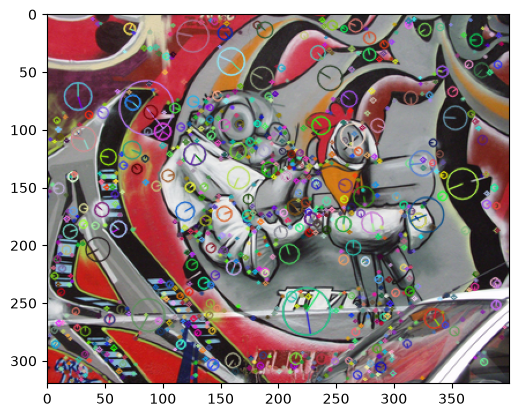

In [3]:
sift = cv2.SIFT_create()
k1, des1 = sift.detectAndCompute(image1,None)
k2, des2 = sift.detectAndCompute(image2,None)

cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image1=cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
plot_image1 = cv2.drawKeypoints(image1, k1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(plot_image1)

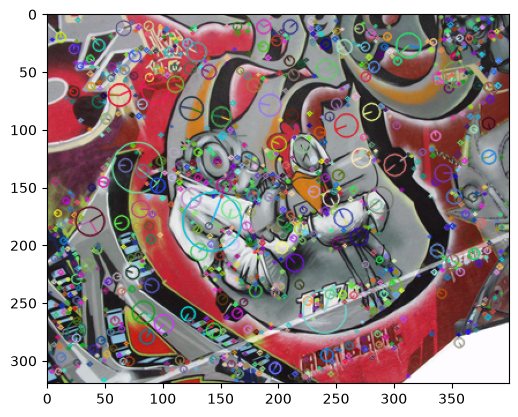

In [4]:
cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)
image2=cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)
plot_image2 = cv2.drawKeypoints(image2, k2, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(plot_image2)

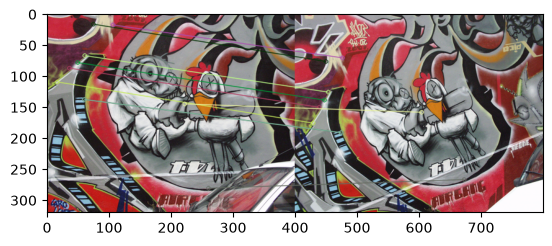

(<matplotlib.image.AxesImage at 0x116f71bd0>, None)

In [5]:
# create BFMatcher object
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)

# Match descriptors.
matches = bf.match(des1, des2)

# Sort them in the order of their distance.
matches = sorted(matches, key=lambda x: x.distance)

# Draw first 10 matches.
image3 = cv2.drawMatches(image1, k1, image2, k2, matches[:10], None, flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)

plt.imshow(image3),plt.show()

Threshold: 10
nonmaxSuppression:True
neighborhood: 2
Total Keypoints with nonmaxSuppression: 3215


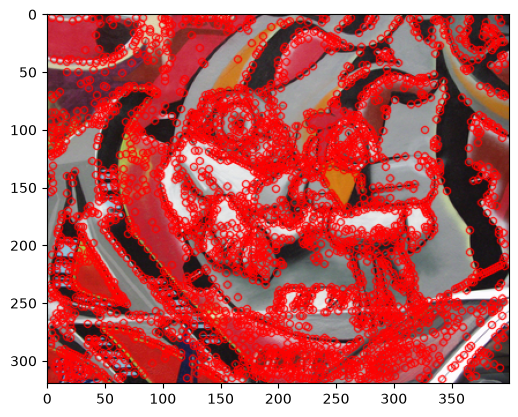

(<matplotlib.image.AxesImage at 0x117028190>, None)

In [6]:
fast = cv2.FastFeatureDetector_create()
 
# find and draw the keypoints
k1 = fast.detect(image1,None)
image4 = cv2.drawKeypoints(image1, k1, None, color=(255,0,0))

# Print all default params
print( "Threshold: {}".format(fast.getThreshold()) )
print( "nonmaxSuppression:{}".format(fast.getNonmaxSuppression()) )
print( "neighborhood: {}".format(fast.getType()) )
print( "Total Keypoints with nonmaxSuppression: {}".format(len(k1)) )

cv2.imshow("fast_true", image4)

plt.imshow(image4),plt.show()

Total Keypoints without nonmaxSuppression: 15500


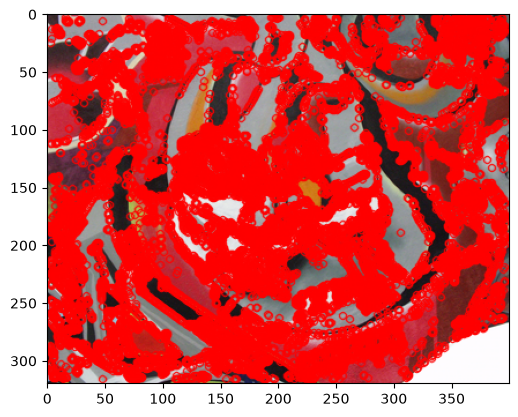

(<matplotlib.image.AxesImage at 0x11706e710>, None)

In [7]:
# Disable nonmaxSuppression
fast.setNonmaxSuppression(0)
k2 = fast.detect(image2, None)
 
print( "Total Keypoints without nonmaxSuppression: {}".format(len(k2)) )
 
image5 = cv2.drawKeypoints(image2, k2, None, color=(255,0,0))

cv2.imshow("fast_false", image5)
plt.imshow(image5),plt.show()

In [8]:
# Initiate FAST detector 

# Initiate BRIEF extractor
brief = cv2.xfeatures2d.FREAK_create()
 
# compute the descriptors with BRIEF
k1, des1 = brief.compute(image1, k1)
 
print( brief.descriptorSize() )
print( des1.shape )

64
(2486, 64)


In [ ]:
cv2.KAZE_create()

< cv2.KAZE 0x116f66410>

: 